# Multivariate Visualization in R

This notebook follows the analysis sequence. Each step explains the operation being performed; data and computational formulas are retained. Run all cells locally to refresh the saved figures.


## Setup and iris profiles


In [2]:
# Load the R packages used by the parallel-coordinate plots and heatmaps.
library(ggplot2)
library(GGally)
library(MASS)
library(fmsb)
library(pheatmap)
library(dplyr) 


Attaching package: ‘dplyr’


The following object is masked from ‘package:MASS’:

    select


The following object is masked from ‘package:ggplot2’:

    vars


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [3]:
# Preview iris records before constructing multivariate displays.
head(iris)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa


In [4]:
# Inspect the range and distribution of iris features.
summary(iris)

  Sepal.Length    Sepal.Width     Petal.Length    Petal.Width   
 Min.   :4.300   Min.   :2.000   Min.   :1.000   Min.   :0.100  
 1st Qu.:5.100   1st Qu.:2.800   1st Qu.:1.600   1st Qu.:0.300  
 Median :5.800   Median :3.000   Median :4.350   Median :1.300  
 Mean   :5.843   Mean   :3.057   Mean   :3.758   Mean   :1.199  
 3rd Qu.:6.400   3rd Qu.:3.300   3rd Qu.:5.100   3rd Qu.:1.800  
 Max.   :7.900   Max.   :4.400   Max.   :6.900   Max.   :2.500  
       Species  
 setosa    :50  
 versicolor:50  
 virginica :50  
                
                
                

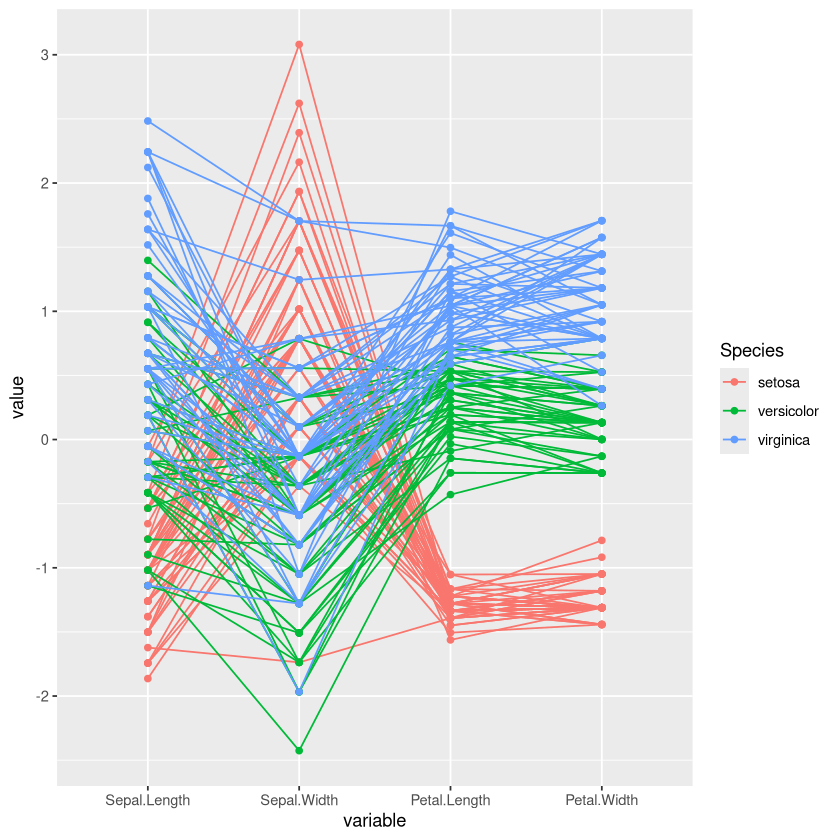

In [5]:
# Draw a standardized parallel-coordinate view colored by species.
ggparcoord(data = iris, 
           columns = 1:4, 
           groupColumn = 5, 
           scale = "std", 
           showPoints = TRUE)

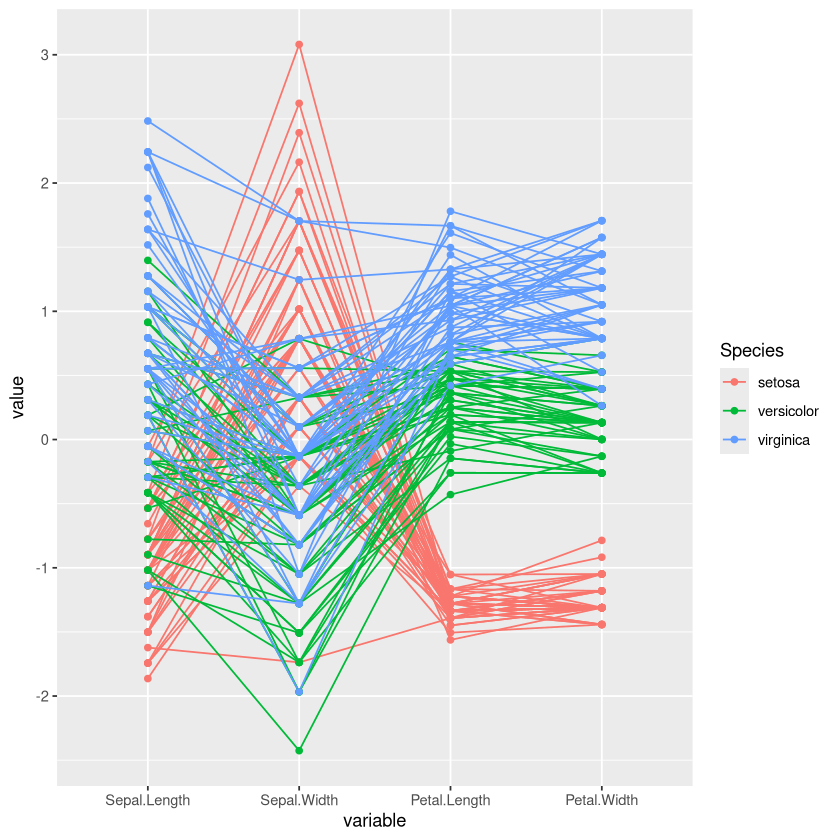

In [6]:
# Repeat the view for visual comparison.
ggparcoord(data = iris, 
           columns = 1:4, 
           groupColumn = 5, 
           scale = "std", 
           showPoints = TRUE)

## Saving and comparing parallel-coordinate displays


In [7]:
# Export the standardized coordinate display as a PNG.
png("img/ggparcoord_parallel_plot.png", width = 1200, height = 800)
ggparcoord(data = iris, 
           columns = 1:4, 
           groupColumn = 5, 
           scale = "std", 
           showPoints = TRUE)
dev.off()

pdf 
  2

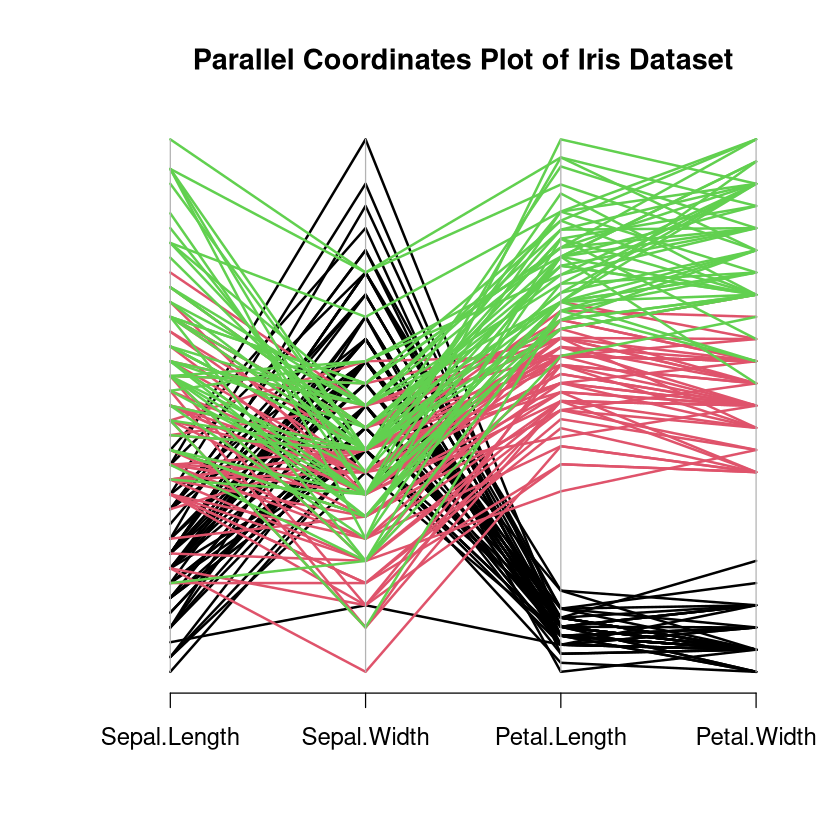

In [8]:
# Use MASS to draw parallel coordinates with a base plotting device.
par(mar = c(5, 5, 4, 2) + 0.1)
par(cex = 1.2)

parcoord(iris[, 1:4], col = as.factor(iris$Species), 
         main = "Parallel Coordinates Plot of Iris Dataset", 
         lwd = 2, 
         pch = 19)

In [9]:
# Save the alternative parallel-coordinate view to disk.
png("img/parcoord_parallel_plot.png", width = 1200, height = 800)
parcoord(iris[, 1:4], col = as.factor(iris$Species), 
         main = "Parallel Coordinates Plot of Iris Dataset", 
         lwd = 2, 
         pch = 19)
dev.off()

pdf 
  2

## Standardized heatmap


In [10]:
# Standardize iris measurements and annotate the rows by species.
iris_scaled <- scale(iris[,1:4])

annotation_colors <- list(Species = c(setosa = "red", versicolor = "green", virginica = "blue"))

pheatmap(iris_scaled, 
         cluster_rows = TRUE, 
         cluster_cols = TRUE, 
         annotation_row = data.frame(Species = iris$Species),
         annotation_colors = annotation_colors)

ERROR: Error in annotation_colors[[colnames(annotation)[i]]]: subscript out of bounds


## Time-series comparison


In [11]:
# Load the bundled time-series data using its updated local path.
appliances <- read.table("data/core_reference/appliance_trends.dat", header=TRUE, sep=",", stringsAsFactors=FALSE)

In [12]:
# Verify the annual appliance values before plotting.
head(appliances)

,calendar_year,dishwasher_count,disposal_count,refrigerator_count,washing_machine_count
,<int>,<int>,<int>,<int>,<int>
1,1960,555,760,3475,3274
2,1961,620,800,3480,3347
3,1962,720,890,3775,3666
4,1963,880,1090,4125,3949
5,1964,1050,1300,4545,4190
6,1965,1290,1355,4870,4347


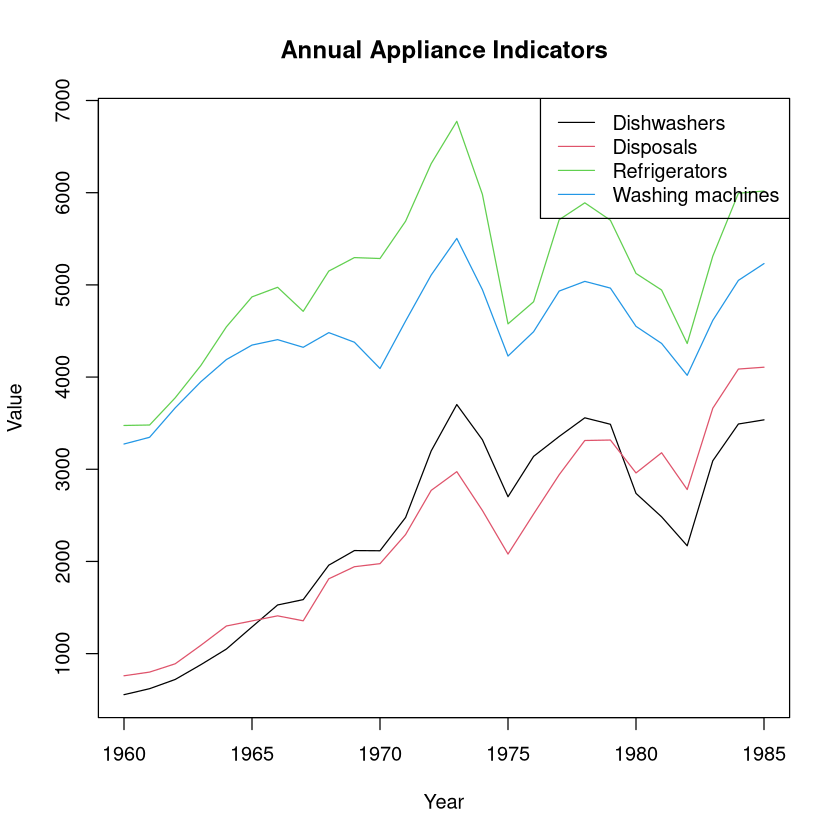

In [13]:
# Compare four annual appliance series in a common coordinate system.
matplot(appliances$calendar_year, appliances[,2:5], type="l", col=1:4, lty=1, xlab="Year", ylab="Value", 
        main="Annual Appliance Indicators")
legend("topright", legend=c("Dishwashers", "Disposals", "Refrigerators", "Washing machines"), col=1:4, lty=1)